In [ ]:
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import seaborn as sns, sklearn, torch
from torch import nn
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor

torch.set_num_threads(1)            # same results run after run on CPU
torch.use_deterministic_algorithms(True)
plt.rcParams['figure.figsize'] = (10, 4)
print('torch', torch.__version__, '| sklearn', sklearn.__version__)

torch 2.11.0+cpu | sklearn 1.6.1


In [ ]:
flights = sns.load_dataset('flights')           # 144 rows: year, month, passengers (Jan 1949 - Dec 1960)
y = pd.Series(flights['passengers'].values,
              index=pd.date_range('1949-01-01', periods=144, freq='MS'), name='passengers')
assert len(y) == 144 and y.sum() == 40363
train, test = y[:'1958'], y['1959':]
H = len(test)                                   # 24 months ahead, all forecast in December 1958

def rmse(f, a): return float(np.sqrt(np.mean((np.asarray(f, float) - np.asarray(a, float)) ** 2)))
def mape(f, a): return float(100 * np.mean(np.abs((np.asarray(f, float) - np.asarray(a, float)) / np.asarray(a, float))))
results = {}

snaive = np.tile(train.values[-12:], 2)         # 1958 copied into 1959 and 1960
results['Seasonal naive'] = (rmse(snaive, test), mape(snaive, test))

In [ ]:
def make_windows(s, p):
    s = np.asarray(s, float)
    X = np.array([s[i - p:i] for i in range(p, len(s))])
    return X, s[p:]

def recursive_forecast(model, history, p, h):     # for scikit-learn models (MLP, linear AR)
    hist = list(np.asarray(history, float)); out = []
    for _ in range(h):
        nxt = float(model.predict(np.array(hist[-p:]).reshape(1, -1))[0])
        out.append(nxt); hist.append(nxt)
    return np.array(out)

def z_of(Lser):
    Lser = np.asarray(Lser, float)                # (1 - B)(1 - B^12) log y, defined from t = 13
    return Lser[13:] - Lser[12:-1] - Lser[1:-12] + Lser[:-13]

def undo(z_future, L_hist):
    Lh = list(L_hist)                             # rebuild log levels month by month
    for zt in z_future:
        Lh.append(zt + Lh[-1] + Lh[-12] - Lh[-13])
    return np.array(Lh[len(L_hist):])

In [ ]:
p = 13
L = np.log(y.values); Ltr = L[:len(train)]
ztr = z_of(Ltr)                                   # 107 values: Feb 1950 - Dec 1958
mz, sz = ztr.mean(), ztr.std()
Xz, tz = make_windows((ztr - mz) / sz, p)         # 94 windows of 13 lags

f_zmean = np.exp(undo(np.full(H, mz), Ltr))       # the transform alone: z forecast = its training mean, no learning
results['Transform, no learning'] = (rmse(f_zmean, test), mape(f_zmean, test))

lin = LinearRegression().fit(Xz, tz)
f_lin = np.exp(undo(recursive_forecast(lin, (ztr - mz) / sz, p, H) * sz + mz, Ltr))
results['Linear AR(13)'] = (rmse(f_lin, test), mape(f_lin, test))

for k, (r, m) in results.items():
    print(f'{k:31s} RMSE {r:6.1f}   MAPE {m:5.1f}%')
assert abs(results['Seasonal naive'][0] - 77.0) < 0.05 and abs(results['Linear AR(13)'][0] - 67.6) < 0.05

Seasonal naive                  RMSE   77.0   MAPE  15.5%
Transform, no learning          RMSE   76.8   MAPE  15.4%
Linear AR(13)                   RMSE   67.6   MAPE  13.2%


In [ ]:
def to_seq(X):                                    # (n, 13) table -> (n, 13, 1) tensor of sequences
    return torch.tensor(np.asarray(X, float), dtype=torch.float32).unsqueeze(-1)

def to_target(t):
    return torch.tensor(np.asarray(t, float), dtype=torch.float32)

print('table:', Xz.shape, '-> sequences:', tuple(to_seq(Xz).shape))

table: (94, 13) -> sequences: (94, 13, 1)


3. The model: the LSTM of the slide, run for real

In [ ]:
class RecurrentForecaster(nn.Module):
    def __init__(self, cell='lstm', hidden=16):
        super().__init__()
        layer = {'lstm': nn.LSTM, 'gru': nn.GRU, 'rnn': nn.RNN}[cell]
        self.rnn = layer(input_size=1, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)
        if cell == 'lstm':
            # PyTorch gate order: input, forget, cell, output
            with torch.no_grad():
                self.rnn.bias_hh_l0[hidden:2 * hidden] += 1.0
    def forward(self, x):
        # x: (batch, 13, 1)
        out, _ = self.rnn(x)
        # out: (batch, 13, hidden), one state per month
        # last state -> next month, shape (batch,)
        return self.head(out[:, -1, :]).squeeze(-1)

print(RecurrentForecaster('lstm'))
print('parameters:', sum(q.numel() for q in RecurrentForecaster('lstm').parameters()))

RecurrentForecaster(
  (rnn): LSTM(1, 16, batch_first=True)
  (head): Linear(in_features=16, out_features=1, bias=True)
)
parameters: 1233


## 4. Training, with the number of epochs chosen on three validation years

In [ ]:
HIDDEN, LR, WD, MAX_EPOCHS = 16, 1e-3, 1e-4, 500
VAL_YEARS = (1956, 1957, 1958)

def fold(year):
    # train: targets before <year>; validation: the 12 targets of <year>
    j = (year - 1949) * 12 - 13                     # position of January <year> in ztr (ztr starts in Feb 1950)
    mv, sv = ztr[:j].mean(), ztr[:j].std()           # scaling from the fitting months only
    Xa, ta = make_windows((ztr[:j + 12] - mv) / sv, p)
    return to_seq(Xa[:-12]), to_target(ta[:-12]), to_seq(Xa[-12:]), to_target(ta[-12:])

def fit_net(model, X, t, epochs, Xv=None, tv=None):  # full batch; returns (training loss, validation loss) per epoch
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
    hist = []
    for ep in range(epochs):
        model.train(); opt.zero_grad()
        loss = ((model(X) - t) ** 2).mean()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        v = np.nan
        if Xv is not None:
            model.eval()
            with torch.no_grad():
                v = ((model(Xv) - tv) ** 2).mean().item()
        hist.append((loss.item(), v))
    return np.array(hist)

def forecast_seq(model, history, p, h):              # recursive, as in the MLP notebook
    hist = list(np.asarray(history, float)); out = []
    model.eval()
    with torch.no_grad():
        for _ in range(h):
            x = torch.tensor(hist[-p:], dtype=torch.float32).view(1, p, 1)
            nxt = model(x).item(); out.append(nxt); hist.append(nxt)
    return np.array(out)

def fit_and_forecast(seed, cell='lstm'):
    curves = []
    for year in VAL_YEARS:                            # 1) validation curves, one per year
        Xf, tf, Xv, tv = fold(year)
        torch.manual_seed(seed)
        model = RecurrentForecaster(cell, HIDDEN)
        curves.append(fit_net(model, Xf, tf, MAX_EPOCHS, Xv, tv)[:, 1])
    ep_best = int(np.argmin(np.mean(curves, axis=0))) + 1   # 2) epoch with the lowest average validation error
    torch.manual_seed(seed)                                 # 3) refit on all training windows, same seed
    model = RecurrentForecaster(cell, HIDDEN)
    fit_net(model, to_seq(Xz), to_target(tz), ep_best)
    zf = forecast_seq(model, (ztr - mz) / sz, p, H) * sz + mz
    return np.exp(undo(zf, Ltr)), ep_best, np.array(curves)

epochs chosen on 1956-1958: 128
LSTM (seed 0)   RMSE 84.0   MAPE 16.6%


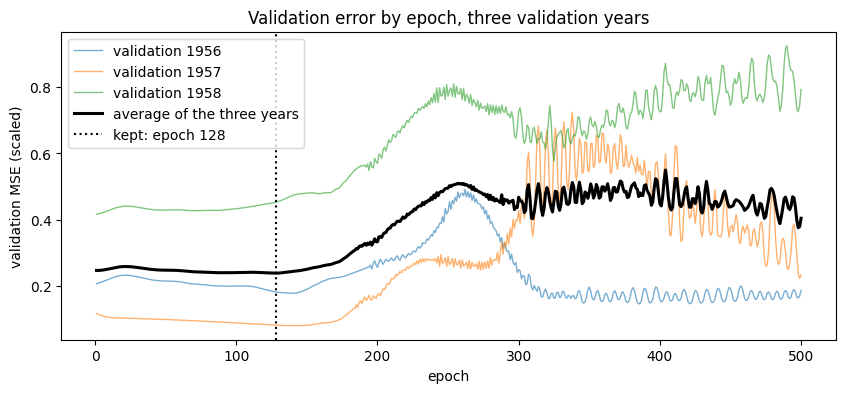

In [ ]:
f_lstm0, ep0, curves0 = fit_and_forecast(0, 'lstm')
results['LSTM (seed 0)'] = (rmse(f_lstm0, test), mape(f_lstm0, test))
print(f'epochs chosen on 1956-1958: {ep0}')
print('LSTM (seed 0)   RMSE %.1f   MAPE %.1f%%' % results['LSTM (seed 0)'])

ep = np.arange(1, MAX_EPOCHS + 1)
for year, c in zip(VAL_YEARS, curves0):
    plt.plot(ep, c, lw=1, alpha=.6, label=f'validation {year}')
plt.plot(ep, curves0.mean(0), 'k', lw=2.2, label='average of the three years')
plt.axvline(ep0, color='k', ls=':', label=f'kept: epoch {ep0}')
plt.xlabel('epoch'); plt.ylabel('validation MSE (scaled)'); plt.legend()
plt.title('Validation error by epoch, three validation years'); plt.show()

### 6. Ten seeds, for the LSTM and for a GRU

One run is not evidence. Each seed changes the initial weights; everything else is identical. The average of the runs is taken in log scale, as in the MLP notebook. (About 2-5 minutes.)

In [ ]:
SEEDS = range(10)
runs, rmse_seed, epochs_seed = {}, {}, {}
for cell in ('lstm', 'gru'):
    out = [fit_and_forecast(s, cell) for s in SEEDS]
    runs[cell] = np.array([o[0] for o in out])
    rmse_seed[cell] = [rmse(f, test) for f in runs[cell]]
    epochs_seed[cell] = [o[1] for o in out]
    f_avg = np.exp(np.log(runs[cell]).mean(0))
    results[f'{cell.upper()}, average of 10 seeds'] = (rmse(f_avg, test), mape(f_avg, test))
    r = rmse_seed[cell]
    print(f'{cell.upper()}: RMSE over seeds min {min(r):.1f}  median {np.median(r):.1f}  max {max(r):.1f};'
          f'  average of runs {results[f"{cell.upper()}, average of 10 seeds"][0]:.1f};  epochs {epochs_seed[cell]}')

In [ ]:
def mlp_forecast(seed):
    net = MLPRegressor(hidden_layer_sizes=(32,), activation='relu', alpha=1e-3, max_iter=5000, random_state=seed)
    net.fit(Xz, tz)
    zf = recursive_forecast(net, (ztr - mz) / sz, p, H) * sz + mz
    return np.exp(undo(zf, Ltr))

runs['mlp'] = np.array([mlp_forecast(s) for s in SEEDS])
rmse_seed['mlp'] = [rmse(f, test) for f in runs['mlp']]
f_mlp_avg = np.exp(np.log(runs['mlp']).mean(0))
results['MLP, average of 10 seeds'] = (rmse(f_mlp_avg, test), mape(f_mlp_avg, test))
print('MLP, average of 10 seeds   RMSE %.1f   MAPE %.1f%%' % results['MLP, average of 10 seeds'])


In [ ]:
table = pd.DataFrame(results, index=['RMSE', 'MAPE']).T
table.index.name = 'model'

In [ ]:
f_lstm_avg = np.exp(np.log(runs['lstm']).mean(0))
plt.plot(test.index, runs['lstm'].T, color='C0', alpha=.2)
plt.plot(test.index, f_lstm_avg, 'C0', lw=2.5, label='LSTM, average of 10 seeds')
plt.plot(test.index, f_mlp_avg, 'C2', lw=1.8, label='MLP, average of 10 seeds')
plt.plot(test.index, f_lin, 'C1', lw=1.8, label='linear AR(13)')
plt.plot(test.index, test, 'k', lw=2, label='observed')
plt.legend(); plt.title('1959-1960, all forecasts made in December 1958'); plt.show()